# 🏠 Projeto 2º Bimestre — Notebook 1: Entendimento do Problema & Data Wrangling
**Disciplina:** Ciência de Dados &nbsp;|&nbsp; **Etapa:** Entrega 0 / Checkpoint 1 (Aula 09 — *Data Wrangling*)

---

## 1. Entendimento do Negócio (CRISP-DM)

**Problema de negócio:** Imóveis residenciais situados em zonas de maior renda média, com maior número de cômodos e com carga tributária (IPTU) proporcionalmente mais alta, possuem correlação estatisticamente significante maior com valores de mercado elevados e com classificação em **zonas nobres** do que propriedades em regiões periféricas.

**Decisão que o projeto apoia:** precificar imóveis, segmentar zonas da cidade e classificar automaticamente o tipo de zona (Nobre, Urbana ou Suburbana) para apoiar decisões de investimento imobiliário e de política tributária.

| Elemento | Definição |
| :--- | :--- |
| **Fonte** | Base pública Kaggle — *California Housing Prices* (Censo de 1990) |
| **Multiplicador de mundo real** | $M_{real} = 1{,}0\times$ (base pública) |
| **Alvo contínuo (Regressão)** | `Valor_Imovel_Mil_BRL` |
| **Variáveis para Clustering** | `Valor_Imovel_Mil_BRL`, `Imposto_IPTU_Anual_BRL`, `Renda_Media_Zona_Mil_BRL`, `Media_Comodos_Por_Casa` |
| **Alvo categórico (Classificação futura)** | `Tipo_Zona` (Nobre / Urbana / Suburbana) |

> ⚠️ **Transparência metodológica (leia e ajuste com o grupo):**
> A base original do Kaggle **não possui** as colunas `Imposto_IPTU_Anual_BRL` nem `Tipo_Zona`, e seus valores estão em **dólares de 1990**. Por isso, a Seção 3 documenta a **engenharia de atributos**:
> 1. **Conversão USD → BRL** com cotação fixa e parametrizável (`COTACAO_USD_BRL`).
> 2. **IPTU sintético** = valor do imóvel × alíquota aleatória (0,6% a 1,4%, com semente fixa). Como depende do valor, ele **não deve ser usado como preditor** do `Valor_Imovel_Mil_BRL` na Regressão (vazamento / circularidade). Se o grupo conseguir uma tabela real de alíquotas, substitua esta etapa.
> 3. **`Tipo_Zona`** definido por percentis da renda média da zona (regra explícita abaixo). Na Classificação futura, **não use `Renda_Media_Zona_Mil_BRL` como preditor** (ela define o rótulo).

## 2. Como obter o dataset (você ainda não tem o arquivo)
1. Baixe em: https://www.kaggle.com/datasets/camnugent/california-housing-prices (arquivo **`housing.csv`**).
2. Coloque o `housing.csv` **na mesma pasta deste notebook** (no Colab: ícone de pasta → upload).
3. Rode o notebook. Ele cria automaticamente o **`housing_tax_data.csv`** (base do projeto, já com as colunas em R$) e, ao final, o **`housing_tax_data_limpo.csv`** usado no Notebook 2 (Clustering).

> Alternativa via código (precisa de conta/token Kaggle): `pip install kagglehub` e `kagglehub.dataset_download("camnugent/california-housing-prices")`.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
 
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

# ----------------------- PARÂMETROS DO PROJETO -----------------------
SEED = 42
COTACAO_USD_BRL = 5.0            # cotação fixa documentada (altere se o grupo preferir)
ARQ_KAGGLE  = 'housing.csv'                # arquivo original baixado do Kaggle
ARQ_PROJETO = 'housing_tax_data.csv'       # base do projeto (colunas em R$ + IPTU + Tipo_Zona)
ARQ_LIMPO   = 'housing_tax_data_limpo.csv' # saída deste notebook -> entrada do Notebook 2
COLUNAS_CLUSTER = ['Valor_Imovel_Mil_BRL', 'Imposto_IPTU_Anual_BRL',
                   'Renda_Media_Zona_Mil_BRL', 'Media_Comodos_Por_Casa']

## 3. Construção da base do projeto (ETL a partir do `housing.csv`)

Mapeamento das colunas originais para as colunas do projeto:

| Coluna do projeto | Origem / Regra |
| :--- | :--- |
| `Valor_Imovel_Mil_BRL` | `median_house_value` × cotação ÷ 1000 |
| `Renda_Media_Zona_Mil_BRL` | `median_income` (em dezenas de milhares de USD/ano) × 10 × cotação |
| `Media_Comodos_Por_Casa` | `total_rooms` ÷ `households` |
| `Imposto_IPTU_Anual_BRL` | **Sintético:** valor do imóvel × alíquota sorteada em U(0,6%; 1,4%) |
| `Tipo_Zona` | Renda ≥ percentil 75 → **Nobre**; Renda ≤ percentil 35 → **Suburbana**; demais → **Urbana** |

In [4]:
def construir_base_projeto(df_k, cotacao=COTACAO_USD_BRL, seed=SEED):
    rng = np.random.default_rng(seed)
    d = pd.DataFrame()
    d['ID_Zona'] = [f'Z_{i+1:05d}' for i in range(len(df_k))]
    d['Valor_Imovel_Mil_BRL'] = (df_k['median_house_value'] * cotacao / 1000).round(2)
    d['Renda_Media_Zona_Mil_BRL'] = (df_k['median_income'] * 10 * cotacao).round(2)
    d['Media_Comodos_Por_Casa'] = (df_k['total_rooms'] / df_k['households'].replace(0, np.nan)).round(3)

    # IPTU sintético (documentado no topo do notebook)
    aliquota = rng.uniform(0.006, 0.014, len(df_k))
    d['Imposto_IPTU_Anual_BRL'] = (d['Valor_Imovel_Mil_BRL'] * 1000 * aliquota).round(2)

    # Tipo_Zona por percentis da renda média da zona
    p75 = d['Renda_Media_Zona_Mil_BRL'].quantile(0.75)
    p35 = d['Renda_Media_Zona_Mil_BRL'].quantile(0.35)
    d['Tipo_Zona'] = np.select(
        [d['Renda_Media_Zona_Mil_BRL'] >= p75, d['Renda_Media_Zona_Mil_BRL'] <= p35],
        ['Nobre', 'Suburbana'], default='Urbana')

    # Colunas originais úteis para interpretação / mapas
    for col in ['longitude', 'latitude', 'housing_median_age', 'total_bedrooms',
                'population', 'households', 'ocean_proximity']:
        d[col] = df_k[col].values
    return d

if os.path.exists(ARQ_PROJETO):
    df_bruto = pd.read_csv(ARQ_PROJETO)
    print(f"✅ '{ARQ_PROJETO}' encontrado e carregado.")
elif os.path.exists(ARQ_KAGGLE):
    df_kaggle = pd.read_csv(ARQ_KAGGLE)
    print(f"✅ '{ARQ_KAGGLE}' (Kaggle) carregado: {df_kaggle.shape}. Construindo a base do projeto...")
    df_bruto = construir_base_projeto(df_kaggle)
    df_bruto.to_csv(ARQ_PROJETO, index=False, encoding='utf-8')
    print(f"💾 '{ARQ_PROJETO}' salvo.")
else:
    raise FileNotFoundError(
        f"Nenhum arquivo encontrado. Baixe o 'housing.csv' do Kaggle e coloque na mesma pasta "
        f"do notebook (veja a Seção 2).")

print(f"Dimensões da tabela inicial: {df_bruto.shape[0]} linhas x {df_bruto.shape[1]} colunas")
display(df_bruto.head(8))

✅ 'housing.csv' (Kaggle) carregado: (20640, 10). Construindo a base do projeto...
💾 'housing_tax_data.csv' salvo.
Dimensões da tabela inicial: 20640 linhas x 13 colunas


,ID_Zona,Valor_Imovel_Mil_BRL,Renda_Media_Zona_Mil_BRL,Media_Comodos_Por_Casa,Imposto_IPTU_Anual_BRL,Tipo_Zona,longitude,latitude,housing_median_age,total_bedrooms,population,households,ocean_proximity
0,Z_00001,2263.0,416.26,6.984,27589.70,Nobre,-122.23,37.88,41.0,129.0,322.0,126.0,NEAR BAY
1,Z_00002,1792.5,415.07,6.238,17048.52,Nobre,-122.22,37.86,21.0,1106.0,2401.0,1138.0,NEAR BAY
2,Z_00003,1760.5,362.87,8.288,22655.49,Nobre,-122.24,37.85,52.0,190.0,496.0,177.0,NEAR BAY
3,Z_00004,1706.5,282.15,5.817,19759.47,Nobre,-122.25,37.85,52.0,235.0,558.0,219.0,NEAR BAY
4,Z_00005,1711.0,192.31,6.282,11555.10,Urbana,-122.25,37.85,52.0,280.0,565.0,259.0,NEAR BAY
5,Z_00006,1348.5,201.84,4.762,18616.01,Urbana,-122.25,37.85,52.0,213.0,413.0,193.0,NEAR BAY
6,Z_00007,1496.0,182.96,4.932,18085.32,Urbana,-122.25,37.84,52.0,489.0,1094.0,514.0,NEAR BAY
7,Z_00008,1207.0,156.00,4.798,14832.24,Urbana,-122.25,37.84,52.0,687.0,1157.0,647.0,NEAR BAY


---
## 4. Diagnóstico da Qualidade dos Dados (Aula 09 — Passo 1)
Rastreamos estrutura, tipos, valores nulos, duplicatas, categorias quebradas e anomalias numéricas.

In [5]:
print("=== 4.1 Estrutura e tipos ===")
df_bruto.info()

print("\n=== 4.2 Estatísticas descritivas das variáveis do projeto ===")
display(df_bruto[COLUNAS_CLUSTER].describe().round(2))

print("\n=== 4.3 Valores nulos por coluna ===")
nulos = df_bruto.isnull().sum()
display(nulos[nulos > 0].to_frame('Qtde_NaN').assign(Pct=lambda x: (x['Qtde_NaN']/len(df_bruto)*100).round(2)))

print("=== 4.4 Duplicatas (ignorando o ID artificial) ===")
print("Linhas duplicadas:", df_bruto.drop(columns='ID_Zona').duplicated().sum())

print("\n=== 4.5 Categorias (checando grafias quebradas) ===")
print(df_bruto['Tipo_Zona'].value_counts(dropna=False), "\n")
print(df_bruto['ocean_proximity'].value_counts(dropna=False))

print("\n=== 4.6 Anomalias conhecidas desta base ===")
LIM_VALOR = 500000 * COTACAO_USD_BRL / 1000      # teto de 500 mil USD aplicado pelo Censo
LIM_RENDA = 15 * 10 * COTACAO_USD_BRL            # teto de renda (median_income = 15)
cens_valor = (df_bruto['Valor_Imovel_Mil_BRL'] >= LIM_VALOR).sum()
cens_renda = (df_bruto['Renda_Media_Zona_Mil_BRL'] >= LIM_RENDA).sum()
print(f"Valores censurados no teto (valor >= R$ {LIM_VALOR:,.0f} mil): {cens_valor}")
print(f"Rendas censuradas no teto (renda >= R$ {LIM_RENDA:,.0f} mil): {cens_renda}")
print(f"Valores <= 0: {(df_bruto[COLUNAS_CLUSTER] <= 0).sum().sum()}")

=== 4.1 Estrutura e tipos ===
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID_Zona                   20640 non-null  str    
 1   Valor_Imovel_Mil_BRL      20640 non-null  float64
 2   Renda_Media_Zona_Mil_BRL  20640 non-null  float64
 3   Media_Comodos_Por_Casa    20640 non-null  float64
 4   Imposto_IPTU_Anual_BRL    20640 non-null  float64
 5   Tipo_Zona                 20640 non-null  str    
 6   longitude                 20640 non-null  float64
 7   latitude                  20640 non-null  float64
 8   housing_median_age        20640 non-null  float64
 9   total_bedrooms            20433 non-null  float64
 10  population                20640 non-null  float64
 11  households                20640 non-null  float64
 12  ocean_proximity           20640 non-null  str    
dtypes: float64(10), str(3)
memory usage: 2.0 M

,Valor_Imovel_Mil_BRL,Imposto_IPTU_Anual_BRL,Renda_Media_Zona_Mil_BRL,Media_Comodos_Por_Casa
count,20640.00,20640.00,20640.00,20640.00
mean,1034.28,10361.98,193.53,5.43
std,576.98,6436.16,94.99,2.47
min,75.00,635.64,25.00,0.85
25%,598.00,5640.73,128.17,4.44
50%,898.50,8781.28,176.74,5.23
75%,1323.62,13396.00,237.16,6.05
max,2500.00,34990.36,750.00,141.91



=== 4.3 Valores nulos por coluna ===


,Qtde_NaN,Pct
total_bedrooms,207,1.0


=== 4.4 Duplicatas (ignorando o ID artificial) ===
Linhas duplicadas: 0

=== 4.5 Categorias (checando grafias quebradas) ===
Tipo_Zona
Urbana       8256
Suburbana    7224
Nobre        5160
Name: count, dtype: int64 

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

=== 4.6 Anomalias conhecidas desta base ===
Valores censurados no teto (valor >= R$ 2,500 mil): 992
Rendas censuradas no teto (renda >= R$ 750 mil): 51
Valores <= 0: 0


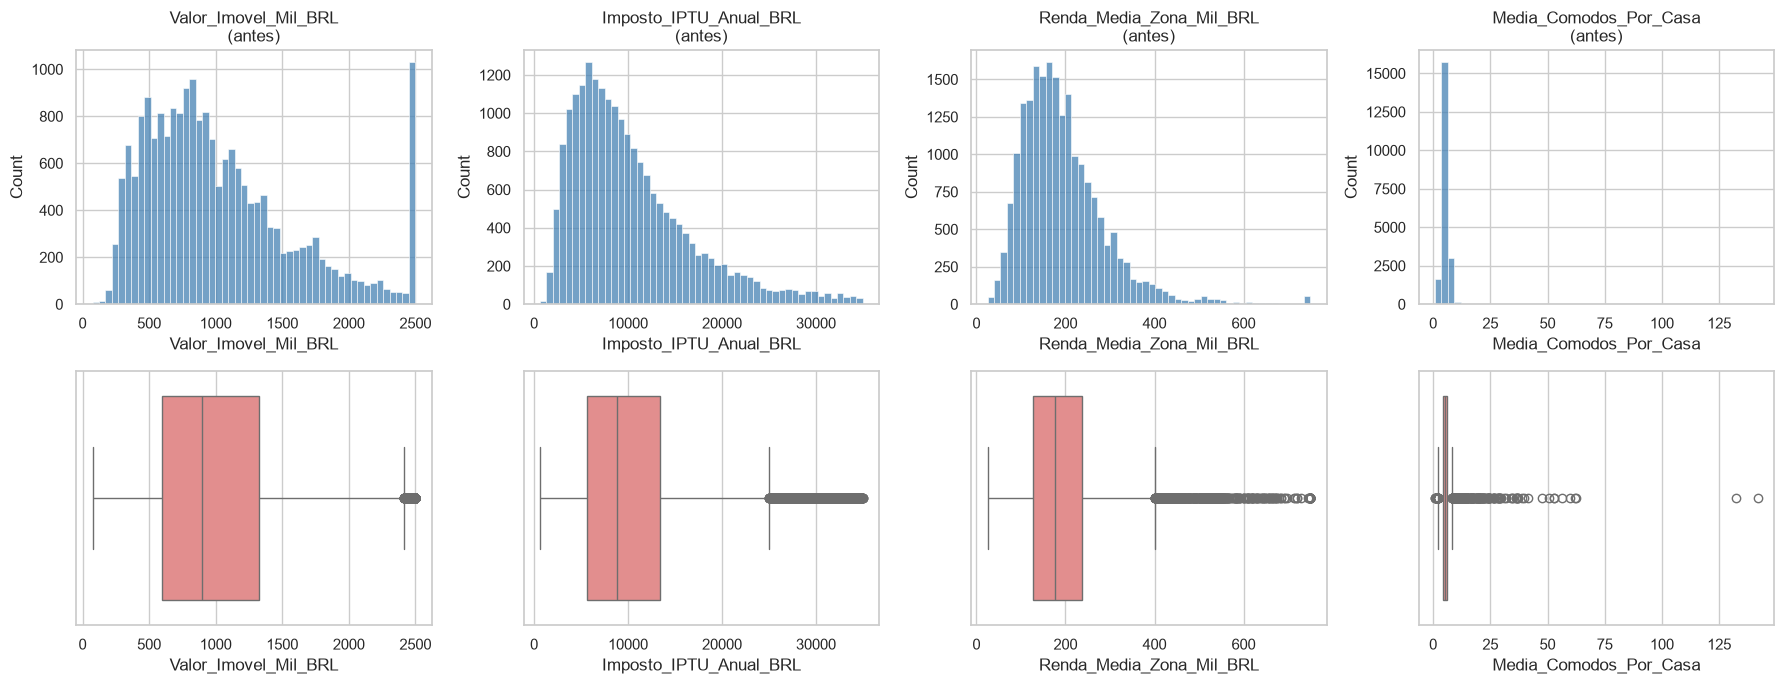

In [6]:
# Visão geral das distribuições ANTES da limpeza
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(COLUNAS_CLUSTER):
    sns.histplot(df_bruto[col], bins=50, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'{col}\n(antes)')
    sns.boxplot(x=df_bruto[col], ax=axes[1, i], color='lightcoral')
plt.tight_layout(); plt.show()

### Achados do diagnóstico e decisões de limpeza
| Problema | Decisão | Justificativa |
| :--- | :--- | :--- |
| Valores de imóvel **censurados** no teto (500 mil USD) | **Remover** | O valor real é desconhecido (≥ teto); manter distorce regressão e clusters. |
| Rendas **censuradas** no teto | **Remover** | Mesmo motivo. |
| `Media_Comodos_Por_Casa` com valores absurdos (ex.: dezenas de cômodos por casa — zonas com poucas residências/hotéis) | **Remover por IQR (k = 3)** | Outliers extremos sequestram a reta e o K-Means. |
| Valores ≤ 0 em variáveis que não podem ser negativas | Converter em `NaN` e remover | Erro de domínio. |
| Textos despadronizados | `.str.strip().str.title()` | Evita categorias duplicadas. |
| `total_bedrooms` com NaN | **Descartar a coluna** | Fora das variáveis do projeto e redundante com `Media_Comodos_Por_Casa`. *(Alternativa: imputar mediana **apenas no treino** na etapa de modelagem.)* |

---
## 5. Limpeza e Filtragem de Outliers (Aula 09 — Passo 2)
Cada etapa registra quantas linhas foram removidas (rastreabilidade para o relatório final).

In [7]:
def outliers_iqr_mask(serie, k=3.0):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return (serie >= q1 - k * iqr) & (serie <= q3 + k * iqr)

df = df_bruto.copy()
log = [('Base bruta', len(df))]

# 1) Duplicatas
df = df.loc[~df.drop(columns='ID_Zona').duplicated(keep='first')].copy()
log.append(('Após remover duplicatas', len(df)))

# 2) Padronização de texto
for col in ['Tipo_Zona', 'ocean_proximity']:
    df[col] = df[col].astype(str).str.strip().str.title()

# 3) Erros de domínio (<= 0) -> NaN
for col in COLUNAS_CLUSTER:
    df.loc[df[col] <= 0, col] = np.nan

# 4) Nulos nas variáveis do projeto -> remover linhas
df = df.dropna(subset=COLUNAS_CLUSTER + ['Tipo_Zona']).copy()
log.append(('Após remover NaN/erros de domínio nas variáveis do projeto', len(df)))

# 5) Valores e rendas censurados no teto
df = df[(df['Valor_Imovel_Mil_BRL'] < LIM_VALOR) & (df['Renda_Media_Zona_Mil_BRL'] < LIM_RENDA)].copy()
log.append(('Após remover registros censurados no teto', len(df)))

# 6) Outliers extremos de Media_Comodos_Por_Casa (IQR k=3)
df = df[outliers_iqr_mask(df['Media_Comodos_Por_Casa'], k=3.0)].copy()
log.append(('Após remover outliers de Media_Comodos_Por_Casa (IQR x3)', len(df)))

# 7) Coluna com NaN fora do escopo
if 'total_bedrooms' in df.columns:
    df = df.drop(columns='total_bedrooms')

df_limpo = df.reset_index(drop=True)

tab_log = pd.DataFrame(log, columns=['Etapa', 'Linhas_Restantes'])
tab_log['Removidas_na_Etapa'] = (-tab_log['Linhas_Restantes'].diff()).fillna(0).astype(int)
display(tab_log)
print(f"\n✅ Base limpa: {df_limpo.shape[0]} linhas ({df_limpo.shape[0]/len(df_bruto)*100:.1f}% da base bruta)")
print("Nulos restantes nas variáveis do projeto:", int(df_limpo[COLUNAS_CLUSTER].isnull().sum().sum()))

,Etapa,Linhas_Restantes,Removidas_na_Etapa
0,Base bruta,20640,0
1,Após remover duplicatas,20640,0
2,Após remover NaN/erros de domínio nas variávei...,20640,0
3,Após remover registros censurados no teto,19645,995
4,Após remover outliers de Media_Comodos_Por_Cas...,19465,180



✅ Base limpa: 19465 linhas (94.3% da base bruta)
Nulos restantes nas variáveis do projeto: 0


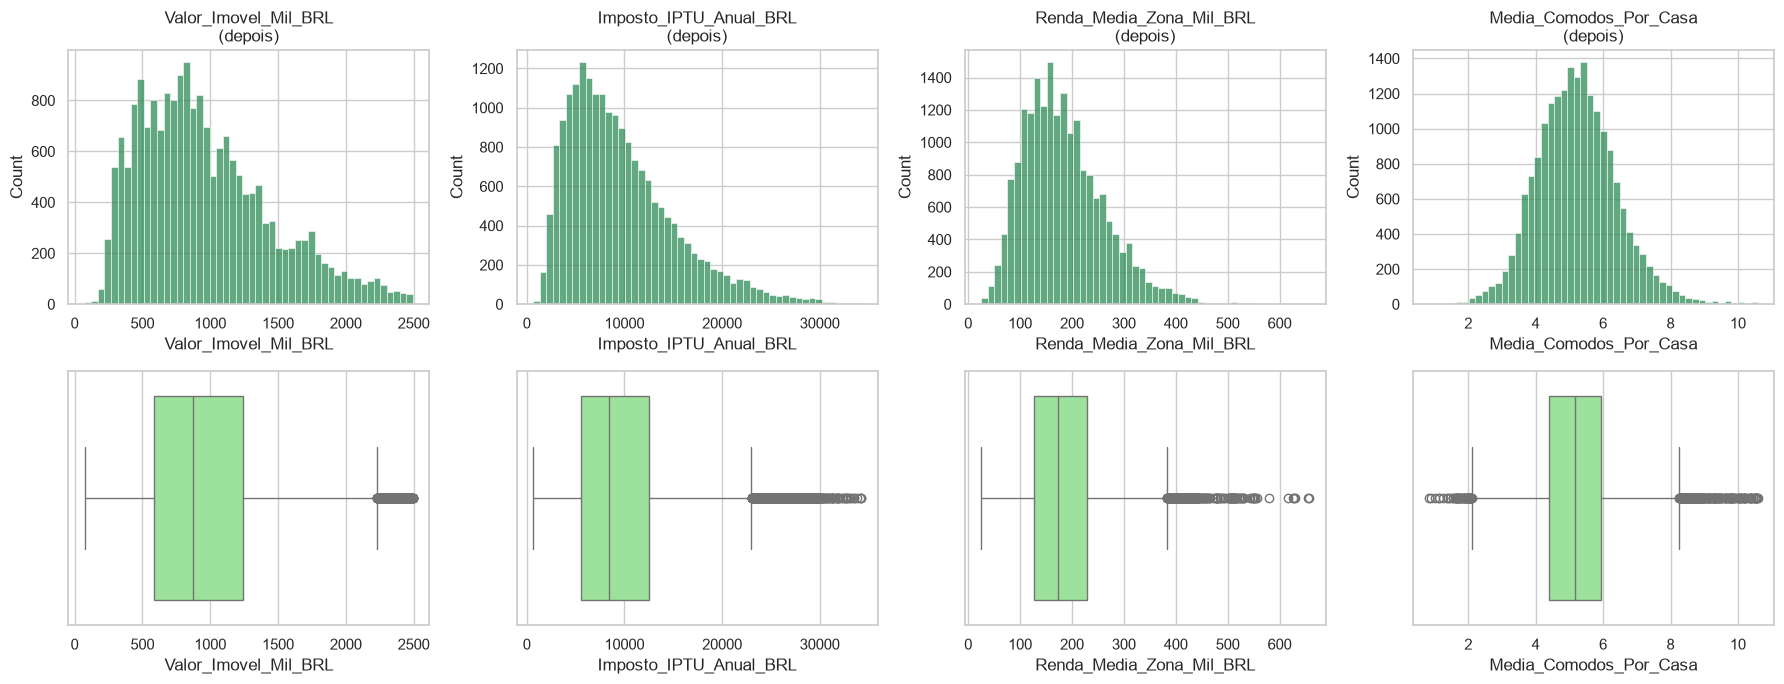

,Valor_Imovel_Mil_BRL,Imposto_IPTU_Anual_BRL,Renda_Media_Zona_Mil_BRL,Media_Comodos_Por_Casa
count,19465.00,19465.00,19465.00,19465.00
mean,961.71,9624.08,183.74,5.22
std,486.01,5482.95,78.23,1.19
min,75.00,635.64,25.00,0.85
25%,583.00,5519.97,126.25,4.41
50%,870.00,8462.54,172.41,5.17
75%,1242.00,12517.98,229.17,5.95
max,2495.50,34246.33,657.38,10.58


Tipo_Zona
Urbana       7992
Suburbana    7126
Nobre        4347
Name: count, dtype: int64


In [8]:
# Visão geral DEPOIS da limpeza
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(COLUNAS_CLUSTER):
    sns.histplot(df_limpo[col], bins=50, ax=axes[0, i], color='seagreen')
    axes[0, i].set_title(f'{col}\n(depois)')
    sns.boxplot(x=df_limpo[col], ax=axes[1, i], color='lightgreen')
plt.tight_layout(); plt.show()

display(df_limpo[COLUNAS_CLUSTER].describe().round(2))
print(df_limpo['Tipo_Zona'].value_counts())

---
## 6. Análise Exploratória Orientada à Hipótese de Negócio
A hipótese afirma que renda, cômodos e IPTU se associam de forma significativa ao valor do imóvel e que zonas nobres têm valores maiores do que as periféricas.

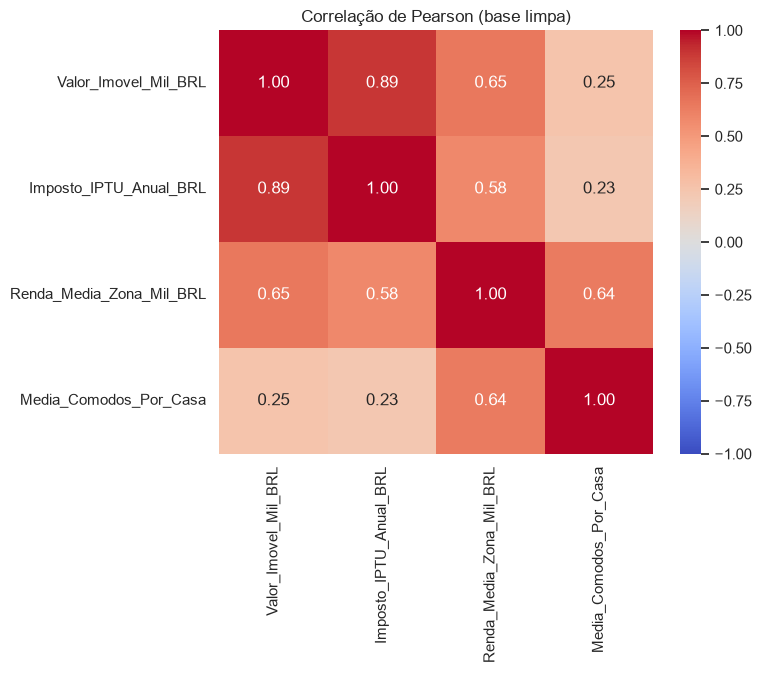

,Variável,r (Pearson),p-valor,Significante (α=5%)
0,Renda_Media_Zona_Mil_BRL,0.6491,0.00e+00,Sim
1,Media_Comodos_Por_Casa,0.2520,8.97e-280,Sim
2,Imposto_IPTU_Anual_BRL,0.8906,0.00e+00,Sim


,Valor_Imovel_Mil_BRL,Imposto_IPTU_Anual_BRL,Renda_Media_Zona_Mil_BRL,Media_Comodos_Por_Casa
Tipo_Zona,,,,
Nobre,1423.79,14329.41,297.89,6.36
Suburbana,655.01,6536.69,109.19,4.51
Urbana,983.85,9817.61,188.13,5.22


Welch t-test (Valor: Nobre vs Suburbana): t = 98.10, p = 0.00e+00


C:\Users\nycol\AppData\Local\Temp\ipykernel_9580\2017745700.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_limpo, x='Tipo_Zona', y='Valor_Imovel_Mil_BRL',


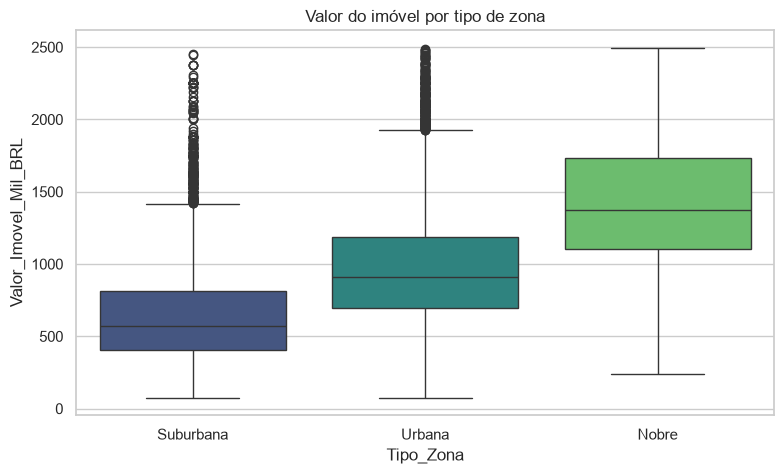

In [9]:
# 6.1 Matriz de correlação de Pearson
corr = df_limpo[COLUNAS_CLUSTER].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlação de Pearson (base limpa)')
plt.show()

# 6.2 Teste de significância: correlação de cada variável com o Valor do Imóvel
linhas = []
for col in ['Renda_Media_Zona_Mil_BRL', 'Media_Comodos_Por_Casa', 'Imposto_IPTU_Anual_BRL']:
    r, p = stats.pearsonr(df_limpo[col], df_limpo['Valor_Imovel_Mil_BRL'])
    linhas.append({'Variável': col, 'r (Pearson)': round(r, 4), 'p-valor': f'{p:.2e}',
                   'Significante (α=5%)': 'Sim' if p < 0.05 else 'Não'})
display(pd.DataFrame(linhas))

# 6.3 Valor médio por tipo de zona + teste de Welch (Nobre vs Suburbana)
display(df_limpo.groupby('Tipo_Zona')[COLUNAS_CLUSTER].mean().round(2))
nobre = df_limpo.loc[df_limpo['Tipo_Zona'] == 'Nobre', 'Valor_Imovel_Mil_BRL']
subur = df_limpo.loc[df_limpo['Tipo_Zona'] == 'Suburbana', 'Valor_Imovel_Mil_BRL']
t, p = stats.ttest_ind(nobre, subur, equal_var=False)
print(f"Welch t-test (Valor: Nobre vs Suburbana): t = {t:.2f}, p = {p:.2e}")

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_limpo, x='Tipo_Zona', y='Valor_Imovel_Mil_BRL',
            order=['Suburbana', 'Urbana', 'Nobre'], palette='viridis')
plt.title('Valor do imóvel por tipo de zona')
plt.show()

> **Leitura crítica (para o relatório):** com dezenas de milhares de linhas, praticamente qualquer correlação é "estatisticamente significante" (p ≈ 0). Por isso, o argumento principal deve usar a **magnitude** de $r$ e a diferença prática entre os grupos, não apenas o p-valor.
> Lembre também: a correlação de `Imposto_IPTU_Anual_BRL` com o valor é **alta por construção** (IPTU sintético = valor × alíquota).

In [10]:
# Salvando a base limpa -> entrada do Notebook 2 (Clustering)
df_limpo.to_csv(ARQ_LIMPO, index=False, encoding='utf-8')
print(f"💾 '{ARQ_LIMPO}' salvo com {df_limpo.shape[0]} linhas e {df_limpo.shape[1]} colunas.")
display(df_limpo.head())

💾 'housing_tax_data_limpo.csv' salvo com 19465 linhas e 12 colunas.


,ID_Zona,Valor_Imovel_Mil_BRL,Renda_Media_Zona_Mil_BRL,Media_Comodos_Por_Casa,Imposto_IPTU_Anual_BRL,Tipo_Zona,longitude,latitude,housing_median_age,population,households,ocean_proximity
0,Z_00001,2263.0,416.26,6.984,27589.70,Nobre,-122.23,37.88,41.0,322.0,126.0,Near Bay
1,Z_00002,1792.5,415.07,6.238,17048.52,Nobre,-122.22,37.86,21.0,2401.0,1138.0,Near Bay
2,Z_00003,1760.5,362.87,8.288,22655.49,Nobre,-122.24,37.85,52.0,496.0,177.0,Near Bay
3,Z_00004,1706.5,282.15,5.817,19759.47,Nobre,-122.25,37.85,52.0,558.0,219.0,Near Bay
4,Z_00005,1711.0,192.31,6.282,11555.10,Urbana,-122.25,37.85,52.0,565.0,259.0,Near Bay


---
## 7. Ficha de Validação do Gatekeeper (Entrega 0)

In [11]:
ficha_gatekeeper = {
    "Grupo_Nome_ou_Numero": "Grupo XX",
    "Integrantes_e_RGM": [
        "1. Nome Completo - RGM",
        "2. Nome Completo - RGM",
        "3. Nome Completo - RGM",
        # "4. Nome Completo - RGM",
    ],
    "Problema_de_Negocio": ("Imóveis em zonas de maior renda média, com mais cômodos e maior carga tributária, "
                            "apresentam maior correlação com valores de mercado elevados e classificação em zonas nobres."),
    "Fonte_Dataset": "Base Pública Kaggle (Multiplicador 1.0x) - California Housing Prices",
    "Arquivo_Dataset_Carregado": "housing_tax_data.csv",
    "Variavel_Alvo_Continua_p_Regressao": "Valor_Imovel_Mil_BRL",
    "Variaveis_Numericas_p_Clustering": COLUNAS_CLUSTER,
    "Variavel_Alvo_Categorica_p_Classificacao_Futura": "Tipo_Zona (Nobre / Urbana / Suburbana)",
}
for chave, valor in ficha_gatekeeper.items():
    print(f"{chave}: {valor}")

Grupo_Nome_ou_Numero: Grupo XX
Integrantes_e_RGM: ['1. Nome Completo - RGM', '2. Nome Completo - RGM', '3. Nome Completo - RGM']
Problema_de_Negocio: Imóveis em zonas de maior renda média, com mais cômodos e maior carga tributária, apresentam maior correlação com valores de mercado elevados e classificação em zonas nobres.
Fonte_Dataset: Base Pública Kaggle (Multiplicador 1.0x) - California Housing Prices
Arquivo_Dataset_Carregado: housing_tax_data.csv
Variavel_Alvo_Continua_p_Regressao: Valor_Imovel_Mil_BRL
Variaveis_Numericas_p_Clustering: ['Valor_Imovel_Mil_BRL', 'Imposto_IPTU_Anual_BRL', 'Renda_Media_Zona_Mil_BRL', 'Media_Comodos_Por_Casa']
Variavel_Alvo_Categorica_p_Classificacao_Futura: Tipo_Zona (Nobre / Urbana / Suburbana)


### ✅ Próximos passos
* **Notebook 2** (`02_Clustering_KMeans.ipynb`): usa o `housing_tax_data_limpo.csv` gerado aqui.
* **Regressão Linear (Aula 10)** também é exigida na Entrega 0 / Checkpoint 1. Lembrete: exclua `Imposto_IPTU_Anual_BRL` dos preditores de `Valor_Imovel_Mil_BRL` e faça `train_test_split` **antes** de qualquer imputação.